# 01 · Preprocessing — Zhang et al. 2019 Follicular Lymphoma (malignant compartment)

Isolate malignant B cells, threshold thin samples, integrate the strongly patient-specific lymphoma batch (Harmony on `sample`), embed, remove detached islands, and check batch mixing + continuity for **Gate 1**. Follicular lymphoma is clonal and patient-private, so the pre-Harmony manifold is a per-patient archipelago; the integration strength is chosen from a sweep read off the **embedding**, not a scalar alone. Deliverable: `processed.h5ad`, `samples.pdf`.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Zhang2019_Hematologic
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Zhang2019_Hematologic | category: Hematologic


### Load malignant compartment

In [ ]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())
print('per-sample:', adata.obs['sample'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Zhang2019_Hematologic
Done.
full atlas: (7002, 24410)
malignant: (5645, 24410) | samples: 4
expression: X max 7.33 (log1p of normalize_total UMI counts)
per-sample: {'FL1018T2': 2405, 'FL2001T2': 1876, 'FL2001T1': 684, 'FL1018T1': 680}


### Sample thresholding (data-driven)
Look for a spillover cliff in the sorted per-sample counts; keep a floor of >=100 so Harmony has enough cells per patient to model the batch. Here all four samples are well-populated (min 680) — no thin sample to drop, so the full malignant set is retained.

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]; gap = int(np.argmax(ratios))
FLOOR = 100
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('largest adjacent ratio %.2f at %d->%d' % (ratios[gap], vals[gap], vals[gap+1]))
thresh = FLOOR
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (floor >={FLOOR}; min kept = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'FL1018T2': np.int64(2405), 'FL2001T2': np.int64(1876), 'FL2001T1': np.int64(684), 'FL1018T1': np.int64(680)}
largest adjacent ratio 2.74 at 1876->684
kept 4/4 samples (floor >=100; min kept = 680) -> 5645 cells


### Overdispersion, PCA, Harmony integration sweep, embedding
Integration strength (`theta`) is swept and judged on same-sample neighbour fraction **and** the regenerated embedding (below). FL's clonal patient batch needs strong integration: mixing improves monotonically through theta=10, which is selected.

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(clonal FL batch: mixing keeps improving to theta=10;',
      'theta=2 leaves a per-patient archipelago, shown below)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 636 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 636
same-sample neighbour fraction | pre-Harmony 0.975 | sweep {2: 0.738, 5: 0.563, 10: 0.453}
selected theta = 10 (clonal FL batch: mixing keeps improving to theta=10; theta=2 leaves a per-patient archipelago, shown below)


### Remove detached islands (data-driven)
Build a UMAP radius graph at 6x the median nearest-neighbour distance, keep the largest connected component — strips physically-detached specks while preserving the continuous body. None detach here.

In [ ]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 0 cells in 0 detached islands


### Cell-cycle compartment check
A small cycling lobe is present; label it so the trajectory root can be kept off proliferation (Gate-2 biology: root at the developmental origin, never a cycling state).

In [ ]:
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
adata.obs['compartment'] = 'Body'; adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('single low-cycling body labelled uniformly (compartment=Body)')

overall cycling fraction: 0.140
single low-cycling body labelled uniformly (compartment=Body)


### Score embryonic modules + house linear orientation
Score Gast/pSom/Crest (union control pool), smooth over the neighbour graph, and define a rigid house orientation `X_umap_lin` (variance axis horizontal, Gast/pSom-high developmental origin on the left) shared by all downstream panels. Smoothing aids orientation only; deliverable panels show RAW scores.

In [ ]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means (honest global readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max()/c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False); theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
origin_score = (S[:,0]+S[:,1]) - S[:,2]; w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f} | house orientation stored as X_umap_lin')

Gast: 57/81 genes present
pSom: 60/98 genes present
Crest: 81/104 genes present
raw module means (honest global readout): {'Gast': 0.0117, 'pSom': 0.0062, 'Crest': 0.0092}
manifold aspect (max/min std): 1.65 | house orientation stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity (judged on the embedding)
iLISI per-neighbourhood, plus the regenerated theta sweep, decide Gate 1 against the embedding itself.

In [ ]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep); idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component, 0 islands removed).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 2.26 of 4 samples
4 samples share one continuous manifold (one connected component, 0 islands removed).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Theta-sweep evidence (embedding, not scalar): under- vs well-integrated

theta=2 segregates by patient (archipelago); theta=10 intermixes -> theta=10 chosen


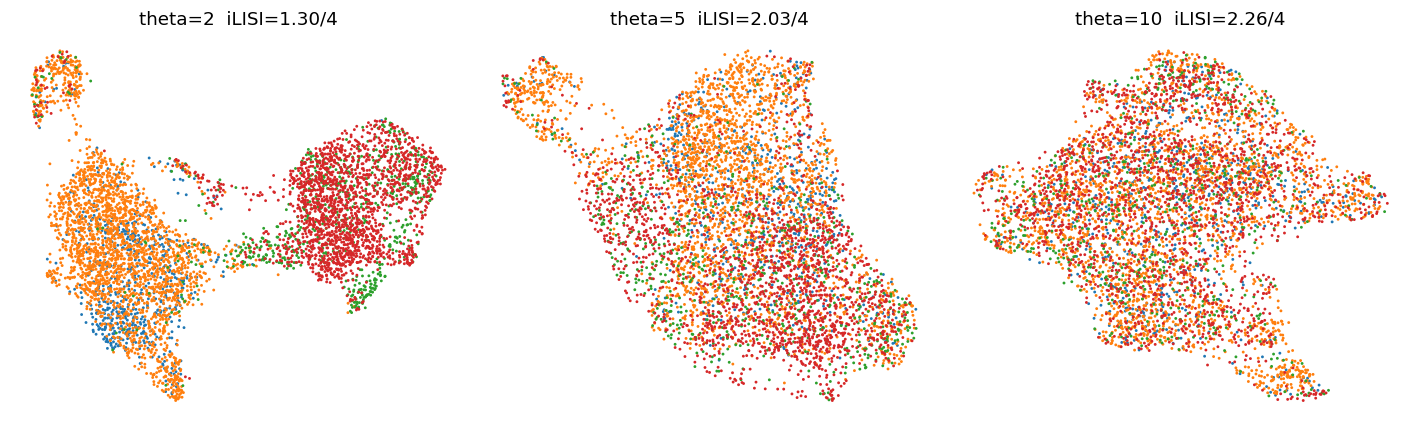

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, th in zip(axes, [2, 5, 10]):
    ad = adata.copy()
    sce.pp.harmony_integrate(ad, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sc.pp.neighbors(ad, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(ad, spread=1.3, random_state=SEED)
    il = np.median(_ilisi(ad.obsm['X_pca_harmony'][:,:20], ad.obs['sample'].values))
    sc.pl.umap(ad, color='sample', size=14, ax=ax, show=False, frameon=False,
               title=f'theta={th}  iLISI={il:.2f}/{n_samp}', legend_loc=None)
plt.tight_layout(); plt.show()
print('theta=2 segregates by patient (archipelago); theta=10 intermixes -> theta=10 chosen')

### Save processed data

In [ ]:
protect = {'sample','compartment','celltype','cell_type','cell_subtype','cell_cycle_phase','patient','progression_status'}
for cc in adata.obs.columns:
    if cc in protect:
        adata.obs[cc] = adata.obs[cc].astype(str).astype('category'); continue
    col = adata.obs[cc]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cc] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (5645, 14715)


### Sample-integration figure (deliverable)
House `(3.5,1.5)` strip on the shared `X_umap_lin` orientation; colour = sample. Intermixing across the strip is the Gate-1 evidence.

saved samples.pdf | cells: 5645


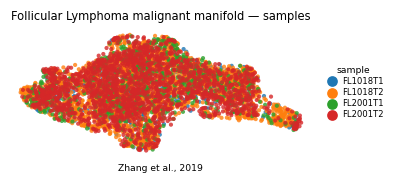

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Follicular Lymphoma malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])